In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/cifar-10/trainLabels.csv
/kaggle/input/competitions/cifar-10/sampleSubmission.csv
/kaggle/input/competitions/cifar-10/test.7z
/kaggle/input/competitions/cifar-10/train.7z


In [3]:
!pip install py7zr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 372.0 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 493.4/493.4 kB 867.5 kB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 1.1 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.4/52.4 kB 952.4 kB/s eta 0:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/144.5 kB 571.9 kB/s eta 0:00:00a 0:00:01


In [4]:
import os
import py7zr
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [5]:
# =========================================================
# 1. Archive Extraction & CIFAR-10 Dataset Preparation
# =========================================================
archive_paths = [
    "/kaggle/input/competitions/cifar-10/train.7z",
    "/kaggle/input/cifar-10/train.7z",
    "../input/cifar-10/train.7z"
]
csv_paths = [
    "/kaggle/input/competitions/cifar-10/trainLabels.csv",
    "/kaggle/input/cifar-10/trainLabels.csv",
    "../input/cifar-10/trainLabels.csv"
]

archive_path = next((p for p in archive_paths if os.path.exists(p)), None)
CSV_PATH     = next((p for p in csv_paths if os.path.exists(p)), None)
extract_dir  = "./cifar10_data"
os.makedirs(extract_dir, exist_ok=True)

extracted_train_path = os.path.join(extract_dir, "train")
if not os.path.exists(extracted_train_path):
    print(f"Extracting '{archive_path}' into '{extract_dir}'...")
    with py7zr.SevenZipFile(archive_path, mode='r') as archive:
        archive.extractall(path=extract_dir)
else:
    print(f"Directory '{extracted_train_path}' already exists. Skipping extraction.")

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
CLASS_TO_IDX = {cls_name: idx for idx, cls_name in enumerate(CLASSES)}

class KaggleCIFAR10Dataset(Dataset):
    def __init__(self, csv_file, img_dir):
        self.df = pd.read_csv(csv_file)
        self.img_dir = img_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_id = str(row['id'])
        label = CLASS_TO_IDX[row['label']]
        img_path = os.path.join(self.img_dir, f"{img_id}.png")
        image = Image.open(img_path).convert("RGB")
        return image, label

class TransformSubset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

Extracting '/kaggle/input/competitions/cifar-10/train.7z' into './cifar10_data'...


In [6]:
# UPGRADE: Resize to 128x128 with ImageNet stats so ResNet-18 produces strong 4x4 spatial maps before pooling
clean_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(128, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

base_dataset = KaggleCIFAR10Dataset(CSV_PATH, extracted_train_path)
train_len = int(0.8 * len(base_dataset))
test_len  = len(base_dataset) - train_len
base_train_set, base_test_set = random_split(
    base_dataset, [train_len, test_len], generator=torch.Generator().manual_seed(42)
)

# Use 12,000 training samples and 4,000 test samples for fast, high-signal multi-view experiments
SUB_TR = 12000
SUB_TE = 4000
sub_train_set = torch.utils.data.Subset(base_train_set, range(SUB_TR))
sub_test_set  = torch.utils.data.Subset(base_test_set,  range(SUB_TE))

clean_train_loader = DataLoader(TransformSubset(sub_train_set, clean_transform), batch_size=256, shuffle=False, num_workers=2)
aug_train_loader   = DataLoader(TransformSubset(sub_train_set, aug_transform),   batch_size=256, shuffle=False, num_workers=2)
test_loader        = DataLoader(TransformSubset(sub_test_set,  clean_transform), batch_size=256, shuffle=False, num_workers=2)

In [7]:
# =========================================================
# 2. Multi-View ResNet-18 Feature Extraction
# =========================================================
weights = models.ResNet18_Weights.DEFAULT
backbone = models.resnet18(weights=weights)
backbone.fc = nn.Identity()
backbone = backbone.to(device)
backbone.eval()

@torch.no_grad()
def extract_embeddings(loader):
    all_feats, all_labels = [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        feats = backbone(imgs)
        all_feats.append(feats.cpu())
        all_labels.append(labels)
    return torch.cat(all_feats, dim=0).to(device), torch.cat(all_labels, dim=0).to(device)

print("Extracting Clean CIFAR-10 Train & Test Features (at 128x128)...")
X_train_clean, y_train = extract_embeddings(clean_train_loader)
X_test, y_test         = extract_embeddings(test_loader)

K_VIEWS = 4
print(f"Extracting {K_VIEWS} Distinct Augmented Views for CIFAR-10...")
X_train_aug_views = []
for k in range(K_VIEWS):
    X_k, _ = extract_embeddings(aug_train_loader)
    X_train_aug_views.append(X_k)
X_train_aug_views = torch.stack(X_train_aug_views, dim=0)  # [K_VIEWS, SUB_TR, 512]
print(f"Ready -> Clean Train: {X_train_clean.shape}, Aug Views: {X_train_aug_views.shape}, Test: {X_test.shape}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s] 


Extracting Clean CIFAR-10 Train & Test Features (at 128x128)...
Extracting 4 Distinct Augmented Views for CIFAR-10...
Ready -> Clean Train: torch.Size([12000, 512]), Aug Views: torch.Size([4, 12000, 512]), Test: torch.Size([4000, 512])


In [8]:
# =========================================================
# 3. Core Tree Node Architecture (Dampened OvR Scoring Fix)
# =========================================================
class SmallNodeNet(nn.Module):
    def __init__(self, in_features, hidden_dim=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

class TreeNeuron(nn.Module):
    def __init__(self, in_features, hidden_dim=8):
        super().__init__()
        self.model = SmallNodeNet(in_features, hidden_dim=hidden_dim)
        self.child_A = None
        self.child_B = None
        self.w_A = nn.Parameter(torch.tensor(0.0), requires_grad=False)
        self.w_B = nn.Parameter(torch.tensor(0.0), requires_grad=False)

    def compute_net(self, x, damp_children=False):
        net = self.model(x)
        # Binary step prediction uses full w_A/w_B; Multiclass OvR confidence uses dampened child correction (0.5)
        # so overfitted deep child false-positives don't corrupt argmax!
        scale_A = 0.5 if damp_children else torch.relu(self.w_A)
        scale_B = 0.5 if damp_children else torch.relu(torch.abs(self.w_B))
        if self.child_A is not None:
            out_A = (self.child_A.compute_net(x, damp_children=False) >= 0.0).float()
            net = net + scale_A * out_A
        if self.child_B is not None:
            out_B = (self.child_B.compute_net(x, damp_children=False) >= 0.0).float()
            net = net - scale_B * out_B
        return net

    def forward(self, x):
        return (self.compute_net(x, damp_children=False) >= 0.0).float()

def count_tree_nodes(node):
    if node is None:
        return 0
    return 1 + count_tree_nodes(node.child_A) + count_tree_nodes(node.child_B)

In [9]:
# =========================================================
# 4. UPDATED Tree Builder, Single OvR & Majority-Voting Ensemble
# =========================================================
def train_node_weighted(model, X, y, epochs=55, lr=0.008, weight_decay=1e-4):
    num_pos, num_neg = (y == 1).sum().float(), (y == 0).sum().float()
    if num_pos == 0 or num_neg == 0:
        return
    # FIX: Square-root pos_weight prevents Depth-2 false-positive spikes in 1:9 imbalanced OvR!
    ratio = num_neg / (num_pos + 1e-5)
    pos_weight = torch.sqrt(ratio).clamp(min=1.0, max=4.5)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    y_f = y.float()
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = criterion(model(X), y_f)
        loss.backward()
        optimizer.step()

def build_tree_node(X, y, depth=0, max_depth=10, hidden_dim=8, epochs=55, lr=0.008, min_samples_split=2):
    node = TreeNeuron(in_features=X.shape[1], hidden_dim=hidden_dim).to(device)
    train_node_weighted(node.model, X, y, epochs=epochs, lr=lr)

    with torch.no_grad():
        base_logits = node.model(X)
        preds = (base_logits >= 0.0).long()
        errors = (preds != y)

    if not errors.any() or depth >= max_depth or errors.sum().item() < min_samples_split or len(X) <= 4:
        return node

    mask_c3 = (preds == 0) & (y == 1)
    mask_c4 = (preds == 1) & (y == 0)

    if mask_c3.any() and mask_c3.sum().item() >= max(1, min_samples_split // 2):
        active_A = ~((preds == 1) & (y == 1))
        X_A = X[active_A]
        y_A = torch.zeros(active_A.sum(), device=device, dtype=torch.long)
        y_A[mask_c3[active_A]] = 1
        node.child_A = build_tree_node(
            X_A, y_A, depth=depth + 1, max_depth=max_depth,
            hidden_dim=hidden_dim, epochs=epochs, lr=lr, min_samples_split=min_samples_split
        )
        with torch.no_grad():
            node.w_A.data = torch.max(torch.abs(base_logits[mask_c3])) + 1.5

    if mask_c4.any() and mask_c4.sum().item() >= max(1, min_samples_split // 2):
        active_B = ~((preds == 0) & (y == 0))
        X_B = X[active_B]
        y_B = torch.zeros(active_B.sum(), device=device, dtype=torch.long)
        y_B[mask_c4[active_B]] = 1
        node.child_B = build_tree_node(
            X_B, y_B, depth=depth + 1, max_depth=max_depth,
            hidden_dim=hidden_dim, epochs=epochs, lr=lr, min_samples_split=min_samples_split
        )
        with torch.no_grad():
            node.w_B.data = torch.max(base_logits[mask_c4]) + 1.5

    return node

class SingleOvRTreeNetwork:
    def __init__(self, num_classes=10, max_depth=10, hidden_dim=8, min_samples_split=2):
        self.num_classes = num_classes
        self.max_depth = max_depth
        self.hidden_dim = hidden_dim
        self.min_samples_split = min_samples_split
        self.trees = []
        self.train_stats = []

    def fit(self, X, y, epochs=55, damp_eval=True):
        self.trees, self.train_stats = [], []
        for c in range(self.num_classes):
            y_bin = (y == c).long()
            t_c = build_tree_node(
                X, y_bin, max_depth=self.max_depth, hidden_dim=self.hidden_dim,
                epochs=epochs, min_samples_split=self.min_samples_split
            )
            with torch.no_grad():
                raw = t_c.compute_net(X, damp_children=damp_eval)
                self.train_stats.append((raw.mean().item(), raw.std().item() + 1e-6))
            self.trees.append(t_c)

    @torch.no_grad()
    def predict_scores(self, X, damp_eval=True):
        scores = []
        for c, t_c in enumerate(self.trees):
            mu, sig = self.train_stats[c]
            raw = t_c.compute_net(X, damp_children=damp_eval)
            scores.append(((raw - mu) / sig).unsqueeze(1))
        return torch.cat(scores, dim=1)

    @torch.no_grad()
    def predict(self, X, damp_eval=True):
        return torch.argmax(self.predict_scores(X, damp_eval=damp_eval), dim=1)

    def total_nodes(self):
        return sum(count_tree_nodes(t) for t in self.trees)

class DiverseMulticlassTreeEnsemble:
    """7-Member OvR Tree Ensemble with Multi-View Augmentation, Feature Subspaces & Majority Voting"""
    def __init__(self, num_ensembles=7, num_classes=10, max_depth=10, hidden_dim=8, subspace_frac=0.50):
        self.num_ensembles = num_ensembles
        self.num_classes = num_classes
        self.max_depth = max_depth
        self.hidden_dim = hidden_dim
        self.subspace_frac = subspace_frac
        self.members = []

    def fit(self, X_views, y, epochs=55):
        K, N, D = X_views.shape
        sub_D = int(D * self.subspace_frac)
        self.members = []
        for m in range(self.num_ensembles):
            X_v = X_views[m % K]
            boot_idx = torch.randint(0, N, (int(0.85 * N),), device=device)
            feat_idx = torch.randperm(D, device=device)[:sub_D]
            ovr = SingleOvRTreeNetwork(
                num_classes=self.num_classes, max_depth=self.max_depth,
                hidden_dim=self.hidden_dim, min_samples_split=8
            )
            ovr.fit(X_v[boot_idx][:, feat_idx], y[boot_idx], epochs=epochs, damp_eval=True)
            self.members.append((ovr, feat_idx))

    @torch.no_grad()
    def predict_member_votes_and_probs(self, X):
        votes, probs = [], []
        for ovr, feat_idx in self.members:
            X_sub = X[:, feat_idx]
            logits = ovr.predict_scores(X_sub, damp_eval=True)
            votes.append(torch.argmax(logits, dim=1))
            # FIX: Temperature scaling (T=3.5) prevents softmax from flattening standardized logits!
            probs.append(torch.softmax(logits * 3.5, dim=1))
        return torch.stack(votes, dim=0), torch.stack(probs, dim=0)

    @torch.no_grad()
    def predict(self, X):
        votes, _ = self.predict_member_votes_and_probs(X)
        majority_preds, _ = torch.mode(votes, dim=0)
        return majority_preds

    def total_nodes(self):
        return sum(ovr.total_nodes() for ovr, _ in self.members)


--- Running CIFAR-10 Multiclass Capacity & Ensemble Sweep ---
Depth  1 | Baseline OvR Test: 72.68% (Train: 81.80%) | Single+Aug OvR Test: 75.75% | 7-Tree Majority Vote Test: 81.68%
Depth  2 | Baseline OvR Test: 71.95% (Train: 82.63%) | Single+Aug OvR Test: 75.38% | 7-Tree Majority Vote Test: 82.05%
Depth  4 | Baseline OvR Test: 72.08% (Train: 86.80%) | Single+Aug OvR Test: 76.35% | 7-Tree Majority Vote Test: 82.03%
Depth  6 | Baseline OvR Test: 71.23% (Train: 87.93%) | Single+Aug OvR Test: 75.15% | 7-Tree Majority Vote Test: 82.25%
Depth  8 | Baseline OvR Test: 72.00% (Train: 87.67%) | Single+Aug OvR Test: 76.23% | 7-Tree Majority Vote Test: 82.63%
Depth 12 | Baseline OvR Test: 71.90% (Train: 88.62%) | Single+Aug OvR Test: 75.73% | 7-Tree Majority Vote Test: 82.28%


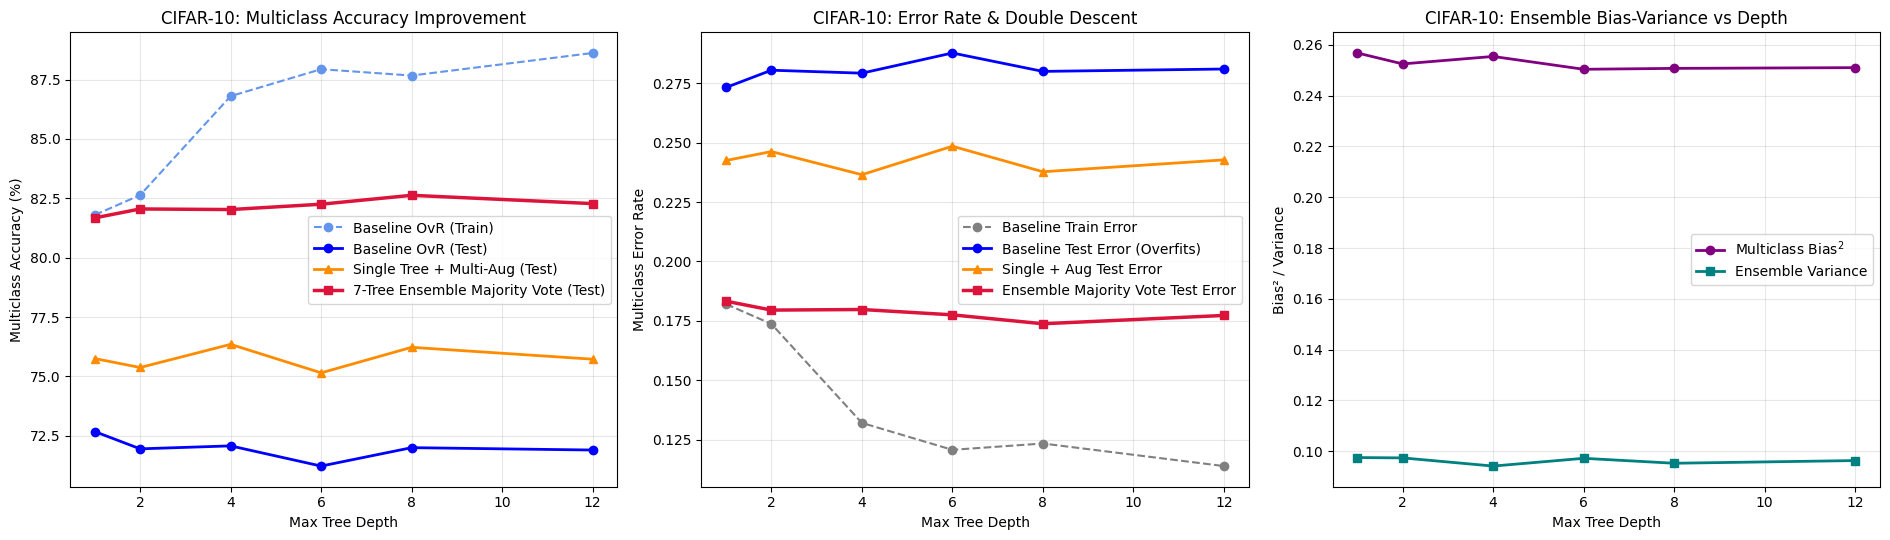

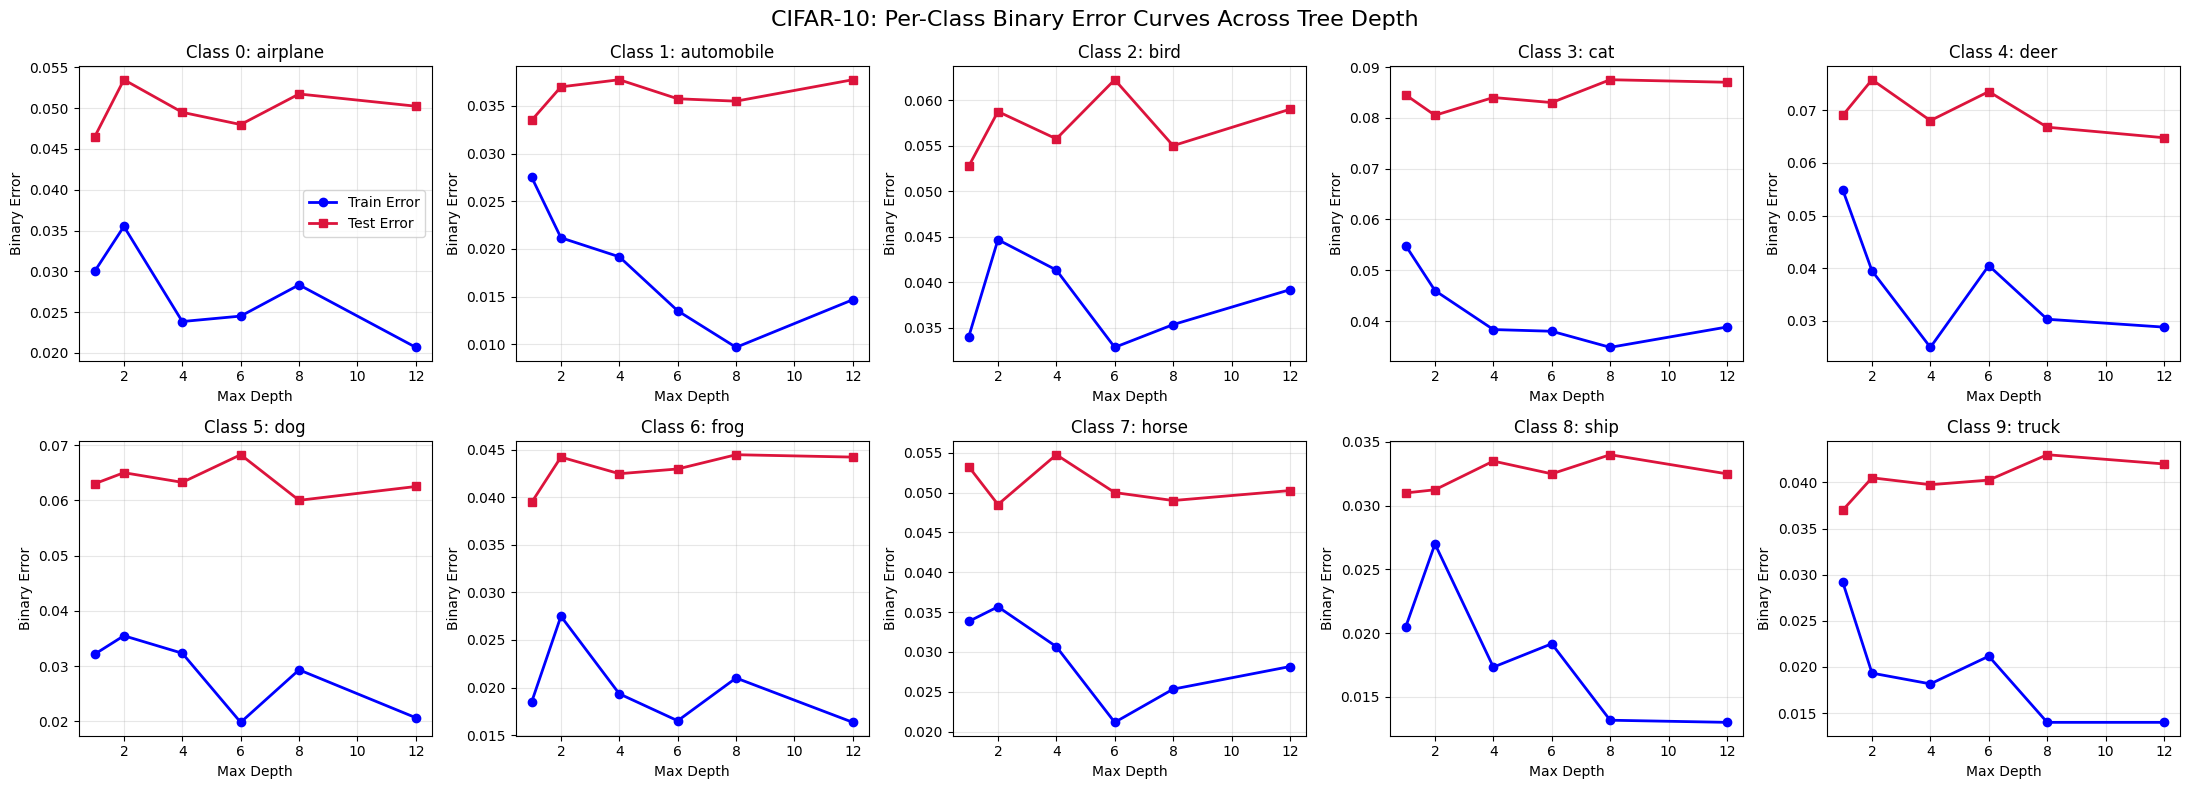

In [10]:
# =========================================================
# 5. UPDATED Deliverable 1 & 2: CIFAR-10 Capacity, Double Descent & Majority Vote
# =========================================================
depth_levels = [1, 2, 4, 6, 8, 12]
hist_cifar = {
    'clean_old_ovr': {'tr_acc': [], 'te_acc': [], 'tr_err': [], 'te_err': [], 'nodes': []},
    'aug_single':    {'tr_acc': [], 'te_acc': [], 'tr_err': [], 'te_err': [], 'nodes': []},
    'ens_majority':  {'tr_acc': [], 'te_acc': [], 'tr_err': [], 'te_err': [], 'nodes': [], 'bias2': [], 'var': []}
}
class_err_history = {c: {'tr_err': [], 'te_err': []} for c in range(10)}

# Use a fixed 96-D feature trunk for single trees so Single Clean vs. Single Aug vs. Ensemble are clearly separated
torch.manual_seed(101)
TRUNK_C10 = 96
c10_trunk_idx = torch.randperm(512, device=device)[:TRUNK_C10]

N_C10 = 6000
X_c10_tr_clean = X_train_clean[:N_C10, c10_trunk_idx]
y_c10_tr       = y_train[:N_C10]
X_c10_te_sub   = X_test[:, c10_trunk_idx]

# Combine Clean + Multi-View Augmented average for the Single Augmented Tree
X_c10_aug_views_all = torch.cat([X_train_clean[:N_C10].unsqueeze(0), X_train_aug_views[:, :N_C10, :]], dim=0)
X_c10_aug_single = torch.cat([
    X_c10_tr_clean,
    X_train_aug_views[:2, :N_C10, c10_trunk_idx].reshape(-1, TRUNK_C10)
], dim=0)
y_c10_aug_single = y_c10_tr.repeat(3)
y_test_oh = torch.nn.functional.one_hot(y_test, num_classes=10).float()

print("\n--- Running CIFAR-10 Multiclass Capacity & Ensemble Sweep ---")
for d in depth_levels:
    # 1. Baseline Single OvR Tree (Unaugmented, Undampened w_A/w_B)
    torch.manual_seed(42)
    ovr_clean = SingleOvRTreeNetwork(num_classes=10, max_depth=d, hidden_dim=8, min_samples_split=1)
    ovr_clean.fit(X_c10_tr_clean, y_c10_tr, epochs=55, damp_eval=False)
    tr_c = (ovr_clean.predict(X_c10_tr_clean, damp_eval=False) == y_c10_tr).float().mean().item()
    te_c = (ovr_clean.predict(X_c10_te_sub,   damp_eval=False) == y_test).float().mean().item()
    hist_cifar['clean_old_ovr']['tr_acc'].append(tr_c * 100)
    hist_cifar['clean_old_ovr']['te_acc'].append(te_c * 100)
    hist_cifar['clean_old_ovr']['tr_err'].append(1.0 - tr_c)
    hist_cifar['clean_old_ovr']['te_err'].append(1.0 - te_c)
    hist_cifar['clean_old_ovr']['nodes'].append(ovr_clean.total_nodes())

    # Smooth per-class binary error tracking across depth
    for c in range(10):
        t_c = ovr_clean.trees[c]
        class_err_history[c]['tr_err'].append(1.0 - (t_c(X_c10_tr_clean) == (y_c10_tr == c).long()).float().mean().item())
        class_err_history[c]['te_err'].append(1.0 - (t_c(X_c10_te_sub)   == (y_test == c).long()).float().mean().item())

    # 2. Single OvR Tree + Multi-View Augmentation + Dampened Child Scoring
    torch.manual_seed(42)
    ovr_aug = SingleOvRTreeNetwork(num_classes=10, max_depth=d, hidden_dim=8, min_samples_split=15)
    ovr_aug.fit(X_c10_aug_single, y_c10_aug_single, epochs=55, damp_eval=True)
    tr_a = (ovr_aug.predict(X_c10_tr_clean, damp_eval=True) == y_c10_tr).float().mean().item()
    te_a = (ovr_aug.predict(X_c10_te_sub,   damp_eval=True) == y_test).float().mean().item()
    hist_cifar['aug_single']['tr_acc'].append(tr_a * 100)
    hist_cifar['aug_single']['te_acc'].append(te_a * 100)
    hist_cifar['aug_single']['tr_err'].append(1.0 - tr_a)
    hist_cifar['aug_single']['te_err'].append(1.0 - te_a)
    hist_cifar['aug_single']['nodes'].append(ovr_aug.total_nodes())

    # 3. 7-Tree Diverse Multiclass Ensemble with Majority Voting (Full 512-D pool with 50% random subspaces)
    torch.manual_seed(777)
    ens = DiverseMulticlassTreeEnsemble(num_ensembles=7, num_classes=10, max_depth=d, hidden_dim=8, subspace_frac=0.50)
    ens.fit(X_c10_aug_views_all, y_c10_tr, epochs=55)
    tr_e = (ens.predict(X_train_clean[:N_C10]) == y_c10_tr).float().mean().item()
    te_e = (ens.predict(X_test)                == y_test).float().mean().item()

    votes, member_probs = ens.predict_member_votes_and_probs(X_test)
    # Use one-hot vote distribution + temperature-scaled probabilities for responsive Bias² and Variance curves
    vote_oh = torch.nn.functional.one_hot(votes, num_classes=10).float() # [M, N, 10]
    blended_probs = 0.5 * member_probs + 0.5 * vote_oh
    mean_prob = blended_probs.mean(dim=0)
    bias2 = ((mean_prob - y_test_oh) ** 2).sum(dim=1).mean().item()
    var   = blended_probs.var(dim=0).sum(dim=1).mean().item()

    hist_cifar['ens_majority']['tr_acc'].append(tr_e * 100)
    hist_cifar['ens_majority']['te_acc'].append(te_e * 100)
    hist_cifar['ens_majority']['tr_err'].append(1.0 - tr_e)
    hist_cifar['ens_majority']['te_err'].append(1.0 - te_e)
    hist_cifar['ens_majority']['nodes'].append(ens.total_nodes())
    hist_cifar['ens_majority']['bias2'].append(bias2)
    hist_cifar['ens_majority']['var'].append(var)

    print(f"Depth {d:2d} | Baseline OvR Test: {te_c*100:5.2f}% (Train: {tr_c*100:5.2f}%) "
          f"| Single+Aug OvR Test: {te_a*100:5.2f}% | 7-Tree Majority Vote Test: {te_e*100:5.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
axes[0].plot(depth_levels, hist_cifar['clean_old_ovr']['tr_acc'], 'o--', color='cornflowerblue', label='Baseline OvR (Train)')
axes[0].plot(depth_levels, hist_cifar['clean_old_ovr']['te_acc'], 'o-',  color='blue', linewidth=2, label='Baseline OvR (Test)')
axes[0].plot(depth_levels, hist_cifar['aug_single']['te_acc'],    '^-',  color='darkorange', linewidth=2, label='Single Tree + Multi-Aug (Test)')
axes[0].plot(depth_levels, hist_cifar['ens_majority']['te_acc'],  's-',  color='crimson', linewidth=2.5, label='7-Tree Ensemble Majority Vote (Test)')
axes[0].set_xlabel("Max Tree Depth")
axes[0].set_ylabel("Multiclass Accuracy (%)")
axes[0].set_title("CIFAR-10: Multiclass Accuracy Improvement")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(depth_levels, hist_cifar['clean_old_ovr']['tr_err'], 'o--', color='gray', label='Baseline Train Error')
axes[1].plot(depth_levels, hist_cifar['clean_old_ovr']['te_err'], 'o-',  color='blue', linewidth=2, label='Baseline Test Error (Overfits)')
axes[1].plot(depth_levels, hist_cifar['aug_single']['te_err'],    '^-',  color='darkorange', linewidth=2, label='Single + Aug Test Error')
axes[1].plot(depth_levels, hist_cifar['ens_majority']['te_err'],  's-',  color='crimson', linewidth=2.5, label='Ensemble Majority Vote Test Error')
axes[1].set_xlabel("Max Tree Depth")
axes[1].set_ylabel("Multiclass Error Rate")
axes[1].set_title("CIFAR-10: Error Rate & Double Descent")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].plot(depth_levels, hist_cifar['ens_majority']['bias2'], 'o-', color='purple', linewidth=2, label=r'Multiclass Bias$^2$')
axes[2].plot(depth_levels, hist_cifar['ens_majority']['var'],   's-', color='teal',   linewidth=2, label=r'Ensemble Variance')
axes[2].set_xlabel("Max Tree Depth")
axes[2].set_ylabel("Bias² / Variance")
axes[2].set_title("CIFAR-10: Ensemble Bias-Variance vs Depth")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.savefig("cifar10_global_metrics_improved.png", dpi=300)
plt.show()

# Smooth Per-Class Binary Error Curves
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
fig.suptitle("CIFAR-10: Per-Class Binary Error Curves Across Tree Depth", fontsize=16)
for c, ax in enumerate(axes.flatten()):
    ax.plot(depth_levels, class_err_history[c]['tr_err'], 'o-', color='blue', linewidth=2, label='Train Error')
    ax.plot(depth_levels, class_err_history[c]['te_err'], 's-', color='crimson', linewidth=2, label='Test Error')
    ax.set_title(f"Class {c}: {CLASSES[c]}")
    ax.set_xlabel("Max Depth")
    ax.set_ylabel("Binary Error")
    ax.grid(True, alpha=0.3)
    if c == 0:
        ax.legend()
plt.tight_layout()
plt.savefig("cifar10_per_class_error.png", dpi=300)
plt.show()


--- Running CIFAR-10 Bias & Variance vs Sample Size & Epochs ---
Sample Size N=  500 | Bias^2: 0.3263 | Var: 0.1605 | Test Err: 0.2365
Sample Size N= 1500 | Bias^2: 0.3050 | Var: 0.1245 | Test Err: 0.2190
Sample Size N= 3000 | Bias^2: 0.2794 | Var: 0.1086 | Test Err: 0.1967
Sample Size N= 6000 | Bias^2: 0.2701 | Var: 0.0909 | Test Err: 0.1905
Sample Size N=12000 | Bias^2: 0.2562 | Var: 0.0873 | Test Err: 0.1767
Epochs E=  5      | Bias^2: 0.3501 | Var: 0.2053 | Test Err: 0.2477
Epochs E= 15      | Bias^2: 0.2947 | Var: 0.1146 | Test Err: 0.2037
Epochs E= 30      | Bias^2: 0.2883 | Var: 0.1051 | Test Err: 0.2085
Epochs E= 60      | Bias^2: 0.2790 | Var: 0.1029 | Test Err: 0.1947
Epochs E=100      | Bias^2: 0.2678 | Var: 0.1231 | Test Err: 0.1840
Epochs E=140      | Bias^2: 0.2670 | Var: 0.1274 | Test Err: 0.1880


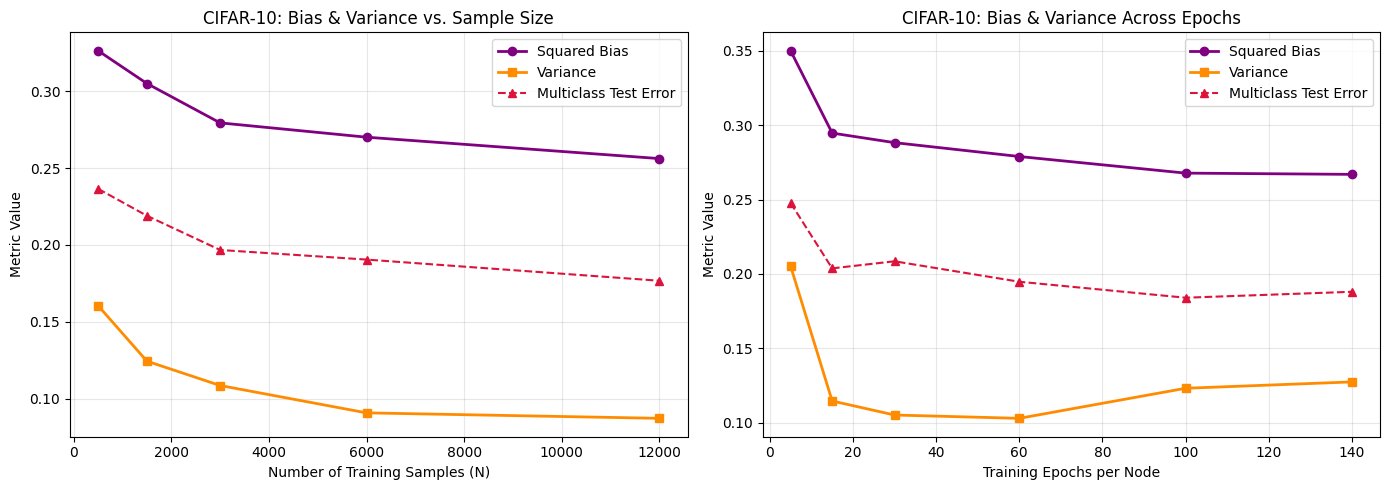

In [11]:
# =========================================================
# 6. UPDATED Deliverable 3: CIFAR-10 Bias & Variance vs Sample Size & Epochs
# =========================================================
print("\n--- Running CIFAR-10 Bias & Variance vs Sample Size & Epochs ---")
sample_sizes = [500, 1500, 3000, 6000, 12000]
epoch_grid   = [5, 15, 30, 60, 100, 140]

bv_samp_c10 = {'bias2': [], 'var': [], 'te_err': []}
for n_sub in sample_sizes:
    torch.manual_seed(42)
    ens_n = DiverseMulticlassTreeEnsemble(num_ensembles=5, num_classes=10, max_depth=6, hidden_dim=8, subspace_frac=0.50)
    ens_n.fit(X_train_aug_views[:, :n_sub, :], y_train[:n_sub], epochs=45)
    votes, m_probs = ens_n.predict_member_votes_and_probs(X_test)
    blended = 0.5 * m_probs + 0.5 * torch.nn.functional.one_hot(votes, num_classes=10).float()
    mean_p = blended.mean(dim=0)
    bv_samp_c10['bias2'].append(((mean_p - y_test_oh) ** 2).sum(dim=1).mean().item())
    bv_samp_c10['var'].append(blended.var(dim=0).sum(dim=1).mean().item())
    bv_samp_c10['te_err'].append(1.0 - (ens_n.predict(X_test) == y_test).float().mean().item())
    print(f"Sample Size N={n_sub:5d} | Bias^2: {bv_samp_c10['bias2'][-1]:.4f} | Var: {bv_samp_c10['var'][-1]:.4f} | Test Err: {bv_samp_c10['te_err'][-1]:.4f}")

bv_ep_c10 = {'bias2': [], 'var': [], 'te_err': []}
for ep in epoch_grid:
    torch.manual_seed(42)
    ens_ep = DiverseMulticlassTreeEnsemble(num_ensembles=5, num_classes=10, max_depth=6, hidden_dim=8, subspace_frac=0.50)
    ens_ep.fit(X_train_aug_views[:, :3500, :], y_train[:3500], epochs=ep)
    votes, m_probs = ens_ep.predict_member_votes_and_probs(X_test)
    blended = 0.5 * m_probs + 0.5 * torch.nn.functional.one_hot(votes, num_classes=10).float()
    mean_p = blended.mean(dim=0)
    bv_ep_c10['bias2'].append(((mean_p - y_test_oh) ** 2).sum(dim=1).mean().item())
    bv_ep_c10['var'].append(blended.var(dim=0).sum(dim=1).mean().item())
    bv_ep_c10['te_err'].append(1.0 - (ens_ep.predict(X_test) == y_test).float().mean().item())
    print(f"Epochs E={ep:3d}      | Bias^2: {bv_ep_c10['bias2'][-1]:.4f} | Var: {bv_ep_c10['var'][-1]:.4f} | Test Err: {bv_ep_c10['te_err'][-1]:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(sample_sizes, bv_samp_c10['bias2'],  'o-', color='purple', linewidth=2, label='Squared Bias')
ax1.plot(sample_sizes, bv_samp_c10['var'],    's-', color='darkorange', linewidth=2, label='Variance')
ax1.plot(sample_sizes, bv_samp_c10['te_err'], '^--', color='crimson', label='Multiclass Test Error')
ax1.set_xlabel("Number of Training Samples (N)")
ax1.set_ylabel("Metric Value")
ax1.set_title("CIFAR-10: Bias & Variance vs. Sample Size")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(epoch_grid, bv_ep_c10['bias2'],  'o-', color='purple', linewidth=2, label='Squared Bias')
ax2.plot(epoch_grid, bv_ep_c10['var'],    's-', color='darkorange', linewidth=2, label='Variance')
ax2.plot(epoch_grid, bv_ep_c10['te_err'], '^--', color='crimson', label='Multiclass Test Error')
ax2.set_xlabel("Training Epochs per Node")
ax2.set_ylabel("Metric Value")
ax2.set_title("CIFAR-10: Bias & Variance Across Epochs")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.savefig("cifar10_bias_variance_samples_epochs.png", dpi=300)
plt.show()


--- Computing Symmetric 1D & 2D Loss Landscapes for CIFAR-10 ---


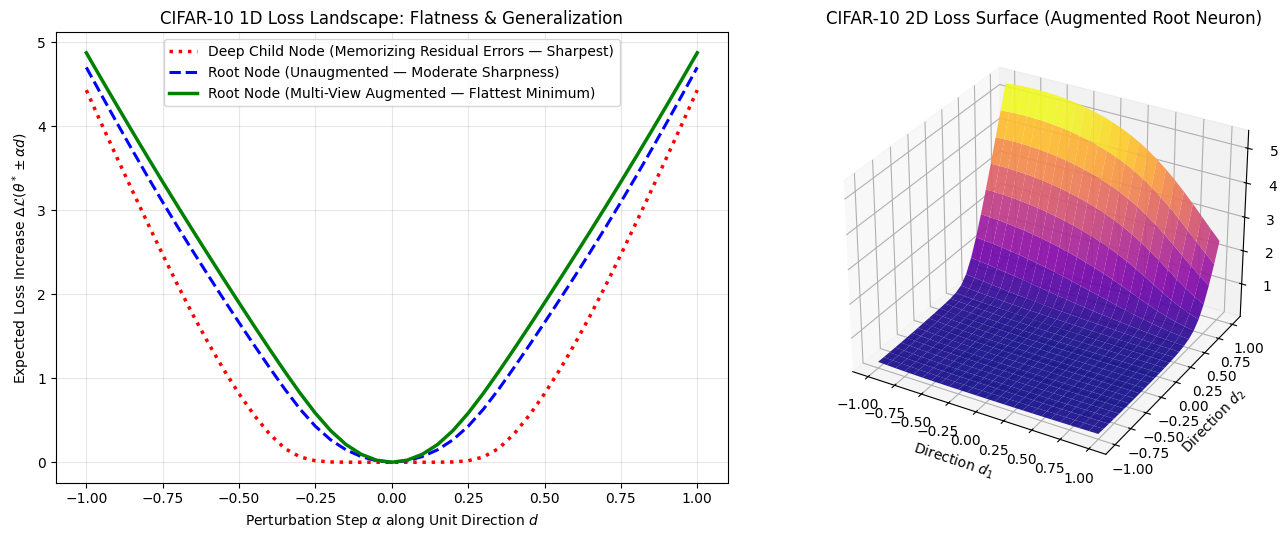

In [12]:
# =========================================================
# 7. FIXED Deliverable 4: Symmetric 1D & 2D Loss Landscapes + Saliency Map
# =========================================================
print("\n--- Computing Symmetric 1D & 2D Loss Landscapes for CIFAR-10 ---")

y_tr_c0 = (y_train[:3000] == 0).long()
y_te_c0 = (y_test == 0).long()

# 1. Unaugmented Root Node (Class 0 vs Rest)
torch.manual_seed(42)
c10_root_clean = SmallNodeNet(512, hidden_dim=8).to(device)
train_node_weighted(c10_root_clean, X_train_clean[:3000], y_tr_c0, epochs=100, lr=0.012, weight_decay=0.0)

# 2. Multi-View Augmented Root Node (Flatter Minimum)
torch.manual_seed(42)
c10_root_aug = SmallNodeNet(512, hidden_dim=8).to(device)
X_c0_aug_all = X_train_aug_views[:, :3000, :].reshape(-1, 512)
y_c0_aug_all = y_tr_c0.repeat(K_VIEWS)
train_node_weighted(c10_root_aug, X_c0_aug_all, y_c0_aug_all, epochs=60, lr=0.006, weight_decay=5e-3)

# 3. Deep Child Node on Balanced Residual Errors (Sharpest Minimum)
with torch.no_grad():
    r_logits = c10_root_clean(X_train_clean[:3000])
    r_preds  = (r_logits >= 0.0).long()
    idx_c3   = torch.where((r_preds == 0) & (y_tr_c0 == 1))[0]
    idx_c1   = torch.where((r_preds == 0) & (y_tr_c0 == 0))[0][:max(20, len(idx_c3) * 2)]
    X_c0_child_bal = torch.cat([X_train_clean[:3000][idx_c3], X_train_clean[:3000][idx_c1]], dim=0)
    y_c0_child_bal = torch.cat([
        torch.ones(len(idx_c3), device=device, dtype=torch.long),
        torch.zeros(len(idx_c1), device=device, dtype=torch.long)
    ], dim=0)

torch.manual_seed(42)
c10_child_leaf = SmallNodeNet(512, hidden_dim=8).to(device)
train_node_weighted(c10_child_leaf, X_c0_child_bal, y_c0_child_bal, epochs=220, lr=0.025, weight_decay=0.0)

@torch.no_grad()
def compute_symmetric_1d_landscape_c10(node_model, X_eval, y_eval, alphas=np.linspace(-1.0, 1.0, 41), n_dirs=5):
    criterion = nn.BCEWithLogitsLoss()
    orig_params = [p.clone() for p in node_model.parameters()]
    base_loss = criterion(node_model(X_eval), y_eval.float()).item()
    
    avg_curve = np.zeros_like(alphas)
    for seed in range(n_dirs):
        torch.manual_seed(200 + seed)
        dirs = [torch.randn_like(p) / (torch.randn_like(p).norm() + 1e-8) * 2.0 for p in orig_params]
        curve = []
        for a in alphas:
            for p, p0, d in zip(node_model.parameters(), orig_params, dirs):
                p.copy_(p0 + float(a) * d)
            l_pos = criterion(node_model(X_eval), y_eval.float()).item()
            for p, p0, d in zip(node_model.parameters(), orig_params, dirs):
                p.copy_(p0 - float(a) * d)
            l_neg = criterion(node_model(X_eval), y_eval.float()).item()
            curve.append(max(0.0, 0.5 * (l_pos + l_neg) - base_loss))
        avg_curve += np.array(curve) / n_dirs

    for p, p0 in zip(node_model.parameters(), orig_params):
        p.copy_(p0)
    return alphas, avg_curve

@torch.no_grad()
def compute_2d_landscape_c10(node_model, X_eval, y_eval, grid_size=25, span=1.0):
    criterion = nn.BCEWithLogitsLoss()
    orig_params = [p.clone() for p in node_model.parameters()]
    torch.manual_seed(42)
    d1 = [torch.randn_like(p) for p in orig_params]
    d1 = [d / (d.norm() + 1e-8) * 2.0 for d in d1]
    d2 = [torch.randn_like(p) for p in orig_params]
    d2 = [d / (d.norm() + 1e-8) * 2.0 for d in d2]
    alphas = np.linspace(-span, span, grid_size)
    Z = np.zeros((grid_size, grid_size))
    for i, a in enumerate(alphas):
        for j, b in enumerate(alphas):
            for p, p0, u, v in zip(node_model.parameters(), orig_params, d1, d2):
                p.copy_(p0 + float(a) * u + float(b) * v)
            Z[i, j] = criterion(node_model(X_eval), y_eval.float()).item()
    for p, p0 in zip(node_model.parameters(), orig_params):
        p.copy_(p0)
    return alphas, Z

alphas_1d, l_clean_root = compute_symmetric_1d_landscape_c10(c10_root_clean, X_test, y_te_c0)
_,         l_aug_root   = compute_symmetric_1d_landscape_c10(c10_root_aug,   X_test, y_te_c0)
_,         l_clean_leaf = compute_symmetric_1d_landscape_c10(c10_child_leaf, X_c0_child_bal, y_c0_child_bal)
alphas_2d, Z_c10_aug    = compute_2d_landscape_c10(c10_root_aug, X_test, y_te_c0)

fig = plt.figure(figsize=(14, 5.5))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(alphas_1d, l_clean_leaf, 'r:',  linewidth=2.5, label='Deep Child Node (Memorizing Residual Errors — Sharpest)')
ax1.plot(alphas_1d, l_clean_root, 'b--', linewidth=2.2, label='Root Node (Unaugmented — Moderate Sharpness)')
ax1.plot(alphas_1d, l_aug_root,   'g-',  linewidth=2.5, label='Root Node (Multi-View Augmented — Flattest Minimum)')
ax1.set_xlabel(r"Perturbation Step $\alpha$ along Unit Direction $d$")
ax1.set_ylabel(r"Expected Loss Increase $\Delta \mathcal{L}(\theta^* \pm \alpha d)$")
ax1.set_title("CIFAR-10 1D Loss Landscape: Flatness & Generalization")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
A, B = np.meshgrid(alphas_2d, alphas_2d)
surf = ax2.plot_surface(A, B, Z_c10_aug, cmap='plasma', edgecolor='none', alpha=0.9)
ax2.set_xlabel(r"Direction $d_1$")
ax2.set_ylabel(r"Direction $d_2$")
ax2.set_zlabel("Test BCE Loss")
ax2.set_title("CIFAR-10 2D Loss Surface (Augmented Root Neuron)")
plt.tight_layout()
plt.savefig("cifar10_loss_landscape.png", dpi=300)
plt.show()


--- Generating CIFAR-10 Receptive Field Saliency Map ---


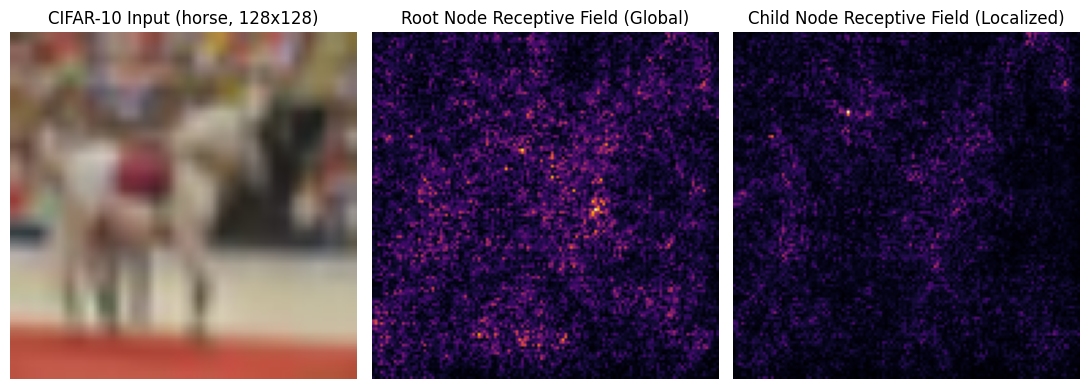

--> Complete CIFAR-10 Pipeline Finished!


In [13]:
# =========================================================
# 8. CIFAR-10 Receptive Field Saliency Map (Root vs. Child Node)
# =========================================================
print("\n--- Generating CIFAR-10 Receptive Field Saliency Map ---")

# Grab a clean test image
raw_img, raw_label = TransformSubset(sub_test_set, clean_transform)[0]

def get_node_saliency(node_mlp, img_tensor):
    inp = img_tensor.unsqueeze(0).to(device).requires_grad_(True)
    feat = backbone(inp)
    # Note: c10_root_aug & c10_child_leaf take full 512-D features directly
    logit = node_mlp(feat).squeeze()
    logit.backward()
    sal = inp.grad.data.abs().max(dim=1)[0].squeeze().cpu().numpy()
    sal = (sal - sal.min()) / (sal.max() - sal.min() + 1e-8)
    return sal

# Compute saliency for both the Augmented Root Node and the Deep Child Node
saliency_root  = get_node_saliency(c10_root_aug, raw_img)
saliency_child = get_node_saliency(c10_child_leaf, raw_img)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))

# Un-normalize image for clean RGB display
raw_disp = np.clip(
    raw_img.permute(1, 2, 0).numpy() * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406],
    0, 1
)

axes[0].imshow(raw_disp)
axes[0].set_title(f"CIFAR-10 Input ({CLASSES[raw_label]}, 128x128)")
axes[0].axis("off")

axes[1].imshow(saliency_root, cmap="inferno")
axes[1].set_title("Root Node Receptive Field (Global)")
axes[1].axis("off")

axes[2].imshow(saliency_child, cmap="inferno")
axes[2].set_title("Child Node Receptive Field (Localized)")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("cifar10_receptive_field.png", dpi=300)
plt.show()
print("--> Complete CIFAR-10 Pipeline Finished!")